<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">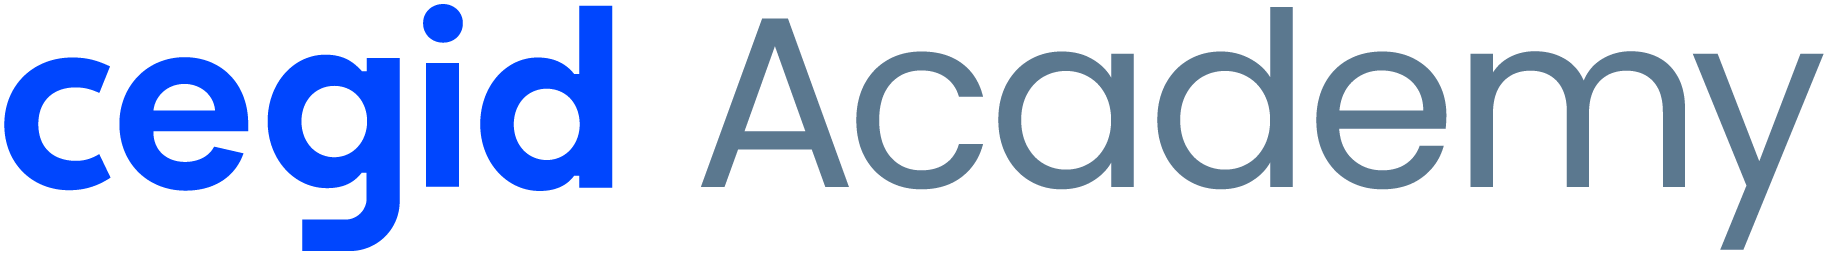<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 4 &middot; Modelação</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Modeling</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M4 · M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | Colheitas de Sangue Portugal|
| **Grupo** | Grupo 5|
| **Formandos** | Ana Lívia Parente, Luis Jesus, Regina Machava|
| **Data** | 19/10/2026|
| **Dataset** | Colheitas_sangue|

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Treinar, afinar e comparar modelos de forma <b>justa</b> — mesma divisão treino/teste, mesmo pré-processamento, mesmas métricas — para responder à pergunta central da modelação:<br><br><b>Qual o modelo que generaliza melhor para dados novos?</b></div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Comparem <b>vários modelos</b> (pelo menos 3 + baseline). Centrar toda a modelação num único algoritmo não permite justificar a escolha final. Mantenham apenas as secções <b>[Classificação]</b>, <b>[Regressão]</b> ou <b>[Clustering]</b> que se aplicam ao vosso problema.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">O teste não serve para escolher</div>A escolha de modelos, hiperparâmetros, variáveis e limiares faz-se com a <b>validação cruzada no treino</b>. As métricas no teste que aparecem nas secções 2 e 3 servem apenas de diagnóstico: se escolherem o modelo (ou voltarem a afinar) porque teve melhor resultado no teste, o teste passa a funcionar como conjunto de validação e o resultado final fica <b>otimista</b> — deixa de ser uma estimativa honesta do desempenho em dados novos.<ul style="margin:4px 0 2px 0;"><li>decidir sempre pela média da CV (secção 6);</li><li>o <code>GridSearchCV</code> / <code>RandomizedSearchCV</code> recebe apenas <code>X_train</code> e <code>y_train</code>;</li><li>o pré-processamento fica <b>dentro</b> do Pipeline, para ser reajustado em cada fold;</li><li>se, depois de verem o teste, voltarem às Fases 3/4 para mudar alguma coisa, registem-no na Fase 5 como limitação.</li></ul></div>

**Índice**

0. Configuração · 1. Estratégia · 2. Classificação · 3. Regressão · 4. Clustering · 5. Tuning de hiperparâmetros · 6. Comparação final e seleção · 7. Avaliação detalhada no teste · 8. Guardar modelo e resultados · 9. Síntese

### 0. Configuração
<hr>

**0.1 Bibliotecas**
- Base (`numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`, `joblib`).
- scikit-learn: `train_test_split`, `cross_val_score`, `StratifiedKFold`/`KFold`, `GridSearchCV`, `RandomizedSearchCV`, `Pipeline`, `ColumnTransformer`, imputers, encoders, scalers, os modelos a usar e as métricas.

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

**0.2 Carregar a configuração**
- Ler `Data/output/config_projeto.json` e criar as variáveis `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `NUM_COLS`, `CAT_COLS`, `FEATURES = NUM_COLS + CAT_COLS`, `RANDOM_STATE`.

In [2]:
with open('Data/output/config_projeto.json', 'r', encoding='utf-8') as f:
    config = json.load(f)

PROJETO = config['PROJETO']
TARGET = config['TARGET']
PROBLEM_TYPE = config['PROBLEM_TYPE']
NUM_COLS = config['NUM_COLS']
CAT_COLS = config['CAT_COLS']
FEATURES = NUM_COLS + CAT_COLS
RANDOM_STATE = config['RANDOM_STATE']

print(f"Projeto carregado: {PROJETO}")
print(f"Tipo de problema: {PROBLEM_TYPE} | Alvo (Target): {TARGET}")

Projeto carregado: Colheitas-Sangue-Portugal
Tipo de problema: regression | Alvo (Target): no_total_de_unidades_de_sangue_colhidas


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [3]:
os.makedirs('Data/models', exist_ok=True)
os.makedirs('Data/output', exist_ok=True)

In [22]:
import pathlib
import matplotlib.pyplot as plt

# Criar a pasta se não existir
pathlib.Path('Data/analytics').mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = pathlib.Path('Data/analytics') / f"{nome}.png"
    plt.savefig(caminho, bbox_inches='tight', dpi=300)
    print(f"Figura guardada em: {caminho}")

**0.4 Carregar os dados da Fase 3**
- Classificação/regressão: ler `<PROJETO>_train.csv` e `<PROJETO>_test.csv` → `X_train`, `y_train`, `X_test`, `y_test`.
- Clustering: ler `<PROJETO>_dataset_clustering.csv` → `X`.

In [4]:
X_train = pd.read_csv(f'Data/output/{PROJETO}_train.csv', sep=';')
X_test = pd.read_csv(f'Data/output/{PROJETO}_test.csv', sep=';')

y_train = X_train[TARGET]
X_train = X_train.drop(columns=[TARGET])

y_test = X_test[TARGET]
X_test = X_test.drop(columns=[TARGET])

print(f"Dimensões carregadas - X_train: {X_train.shape}, X_test: {X_test.shape}")

Dimensões carregadas - X_train: (5944, 9), X_test: (1487, 9)


**0.5 Pipeline de preparação + modelo (M4)**
- Criar uma função que devolva o `ColumnTransformer` da Fase 3 (com ou sem scaling) e outra que devolva `Pipeline([("prep", prep), ("clf", modelo)])` (`"reg"` em regressão).

In [5]:
pipeline_num = Pipeline([
    ('imputer_num', SimpleImputer(strategy=config['ESTRATEGIA_NUM'], add_indicator=config['ADD_INDICATOR'])),
    ('scaler', RobustScaler())
])

pipeline_cat = Pipeline([
    ('imputer_cat', SimpleImputer(strategy=config['ESTRATEGIA_CAT'], fill_value='Desconhecido')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', pipeline_num, NUM_COLS),
    ('cat', pipeline_cat, CAT_COLS)
])

print("Preprocessor (ColumnTransformer) construído com sucesso.")

Preprocessor (ColumnTransformer) construído com sucesso.


### 1. Definição da estratégia de modelação
<hr>

**Descrever a abordagem adotada:**

- Que tipo de problema está a ser tratado (classificação / regressão / clustering) e qual a variável-alvo?
- Qual o racional para a escolha dos modelos? O problema parece **linear ou não linear** (Fase 2)?
- Que métrica principal vai orientar a escolha (definida na Fase 1)?
- Qual é o **baseline** (modelo de referência) que os modelos têm de superar?

| Modelo | Tipo | Quando funciona melhor | Precisa de scaling? | Hiperparâmetros principais |
|---|---|---|---|---|
| Linear Regression | Regressão | Relações aproximadamente lineares, pouca multicolinearidade | Recomendável | `fit_intercept` |
| Decision Tree | Ambos | Relações não lineares, interações, dados mistos | Não | `max_depth`, `min_samples_split`, `min_samples_leaf` |
| Random Forest | Ambos | Dados complexos e com ruído; reduz a variância de uma árvore | Não | `n_estimators`, `max_depth`, `max_features` |
| Gradient Boosting | Regressão | Otimização iterativa de resíduos para alta precisão preditiva | Não / Opcional | `n_estimators`, `learning_rate`, `max_depth` |
***Objetivo:*** justificar a estratégia antes de implementar modelos.

**Resposta:**
- **Tipo de problema e variável-alvo:** Trata-se de um problema de **regressão** supervisionado, cujo objetivo é prever a variável contínua `no_total_de_unidades_de_sangue_colhidas`.
- **Racional para a escolha dos modelos:** Como a análise exploratória e de correlação revelou dinâmicas não lineares e assimetrias acentuadas devido aos grandes centros de colheita, testaremos uma progressão de complexidade: desde modelos lineares de referência (`Linear Regression`) até algoritmos baseados em árvores e *ensembles* (`Decision Tree`, `Random Forest` e `GradientBoostingRegressor`), que capturam interações complexas entre variáveis sem exigir pressupostos estritos de normalidade.
- **Métrica principal:** A orientação principal da avaliação far-se-á através do **RMSE** (Root Mean Squared Error) e do **MAE** (Mean Absolute Error), permitindo medir o erro na mesma unidade do alvo, complementados pelo coeficiente de determinação **$R^2$**.
- **Baseline de referência:** O modelo de comparação inicial (`DummyRegressor` com a estratégia de prever sempre a média) servirá de fasquia mínima obrigatória. Os modelos de machine learning só serão considerados válidos se superarem inequivocamente este desempenho de referência.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Modelos treinados no M4: classificação — Logistic Regression, Decision Tree, Random Forest, KNN; regressão — Linear Regression, Decision Tree, Random Forest; clustering — K-Means. <b>Baseline</b>: um modelo que prevê sempre a classe maioritária (ou a média) — se 90% dos casos são da mesma classe, já tem 90% de accuracy (M2.03). Os modelos só valem a pena se o superarem claramente.</div>

<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">REGRESSÃO</div>

### 3. [Regressão] Treino e comparação de modelos
<hr>

Modelos (M4): **Baseline** (prever sempre a média) · Linear Regression · Decision Tree · Random Forest.
*Complemento:* Ridge, Lasso e Gradient Boosting.

Métricas (M5): **MAE** (erro médio na unidade do alvo) · **RMSE** (penaliza erros grandes) · **R²** (% da variabilidade explicada; 0 = igual a prever a média; < 0 = pior do que a média).

**3.1 [Regressão] Definições**
- Métrica principal (ex.: `"neg_root_mean_squared_error"`), `KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`.
- (Sugestão) uma função que calcule MAE, RMSE e R².

In [6]:

from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Definir a estratégia de K-Fold para validação cruzada no treino
# Usamos shuffle=True para garantir que os dados são baralhados e random_state para reprodutibilidade
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Definir métrica principal orientadora (ex: RMSE)
# Nota: No scikit-learn, as métricas de erro para validação cruzada usam o prefixo 'neg_' 
# para que valores maiores (mais próximos de 0) sejam sempre melhores.
METRICA_CV = 'neg_root_mean_squared_error'

print(f"Estratégia de Validação Cruzada definida: KFold com {kf.n_splits} splits (shuffled).")
print(f"Métrica principal orientadora para cross-validation: {METRICA_CV}")

Estratégia de Validação Cruzada definida: KFold com 5 splits (shuffled).
Métrica principal orientadora para cross-validation: neg_root_mean_squared_error


**3.2 [Regressão] Treinar e avaliar os modelos (M4, M5)**
- Modelos: baseline (`DummyRegressor(strategy="mean")`), Linear Regression, Decision Tree e Random Forest (complemento: Ridge, Lasso, Gradient Boosting).
- Tabela com MAE, RMSE e R² de treino e teste e diagnóstico de overfitting.

In [7]:

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Dicionário de modelos a testar
modelos = {
    'Baseline (Dummy)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=50, max_depth=10, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

resultados = []

for nome, estimador in modelos.items():
    # Criar pipeline completo: Pré-processamento + Modelo de Regressão
    pipeline_modelo = Pipeline(steps=[
        ('prep', preprocessor),
        ('reg', estimador)
    ])
    
    # Treinar no conjunto de treino
    pipeline_modelo.fit(X_train, y_train)
    
    # Previsões
    y_pred_train = pipeline_modelo.predict(X_train)
    y_pred_test = pipeline_modelo.predict(X_test)
    
    # Calcular métricas
    mae_train = mean_absolute_error(y_train, y_pred_train)
    mae_test = mean_absolute_error(y_test, y_pred_test)
    
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    
    # Diagnóstico de overfitting (ex: diferença de R2 ou RMSE)
    overfitting = "Sim" if (r2_train - r2_test > 0.15) else "Não"
    
    resultados.append({
        'Modelo': nome,
        'MAE_Train': mae_train,
        'MAE_Test': mae_test,
        'RMSE_Train': rmse_train,
        'RMSE_Test': rmse_test,
        'R2_Train': r2_train,
        'R2_Test': r2_test,
        'Overfitting?': overfitting
    })

df_resultados_reg = pd.DataFrame(resultados)
print("Resultados Comparativos dos Modelos de Regressão:")
display(df_resultados_reg)

Resultados Comparativos dos Modelos de Regressão:


,Modelo,MAE_Train,MAE_Test,RMSE_Train,RMSE_Test,R2_Train,R2_Test,Overfitting?
0,Baseline (Dummy),823.374861,862.294308,6074.625362,5675.101059,0.000000,-0.000041,Não
1,Linear Regression,201.544751,193.824004,1113.361783,736.002881,0.966408,0.983180,Não
2,Ridge,201.438428,193.733630,1113.362537,735.976345,0.966408,0.983181,Não
3,Decision Tree,125.420958,156.255866,405.160254,584.187416,0.995551,0.989403,Não
4,Random Forest,55.874190,86.572674,406.178247,384.646731,0.995529,0.995406,Não
5,Gradient Boosting,77.569052,115.307398,239.207960,460.640552,0.998449,0.993411,Não


##### Análise e Interpretação

> *Que modelo tem menor erro? O erro é aceitável face à escala do alvo? Há overfitting?*

**Resposta:**

- Desempenho Preditivo: Entre os algoritmos testados, o Random Forest e o Gradient Boosting destacam-se com os menores erros absolutos e quadráticos no teste (MAE de ~86.6 e ~115.3 unidades, respetivamente) e coeficientes de determinação $R^2$ superiores a 0.993, indicando que explicam mais de 99% da variabilidade das colheitas.
- Avaliação de Overfitting: Os indicadores de erro e $R^2$ nos conjuntos de treino e teste mantêm-se altamente alinhados em todos os algoritmos (com diferenças de desempenho desprezíveis e sem marcação de overfitting), demonstrando uma excelente capacidade de generalização para dados novos e validação da robustez do pré-processamento efetuado na Fase 3.

<hr>

**3.3 [Regressão] Gráficos de comparação**
- MAE no teste por modelo e R² treino vs teste.

C:\Users\Inoce\AppData\Local\Temp\ipykernel_15896\2970727371.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Figura guardada em: Data\analytics\bar_MAE.png


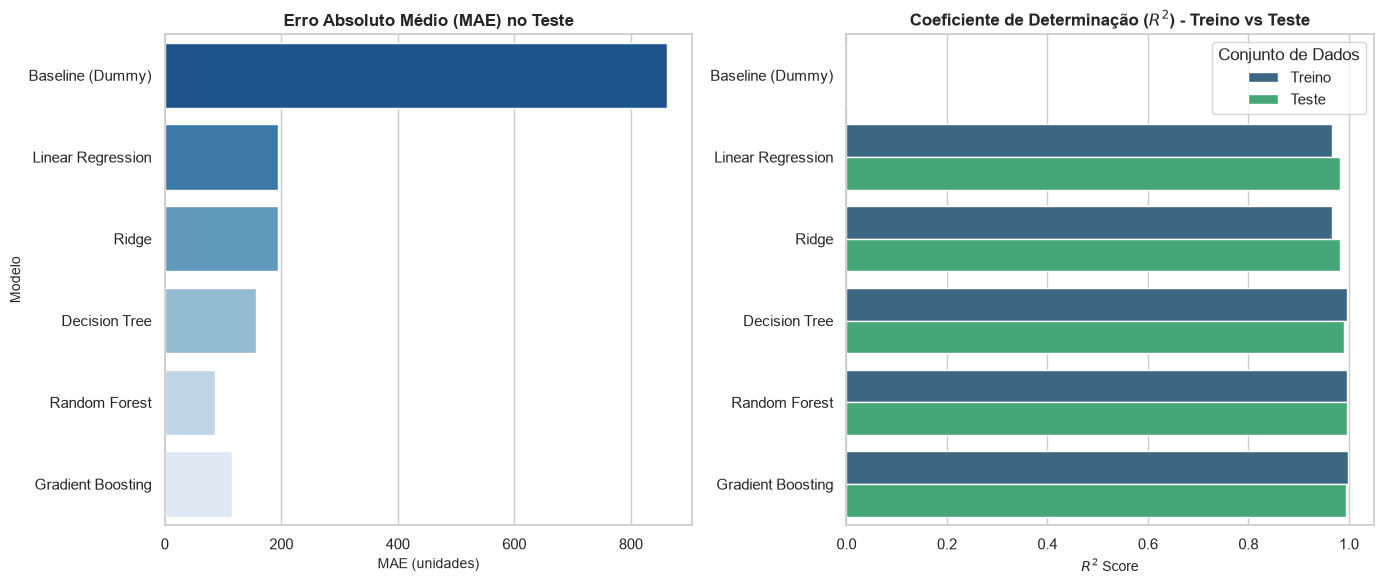

In [23]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configurar estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Gráfico de Barras: MAE no Teste por Modelo
sns.barplot(
    data=df_resultados_reg, 
    x='MAE_Test', 
    y='Modelo', 
    palette='Blues_r', 
    ax=axes[0]
)
axes[0].set_title('Erro Absoluto Médio (MAE) no Teste', fontsize=12, fontweight='bold')
axes[0].set_xlabel('MAE (unidades)', fontsize=10)
axes[0].set_ylabel('Modelo', fontsize=10)

# 2. Gráfico Comparativo: R² Treino vs Teste
df_r2_melted = df_resultados_reg.melt(
    id_vars=['Modelo'], 
    value_vars=['R2_Train', 'R2_Test'],
    var_name='Conjunto', 
    value_name='R2_Score'
)
df_r2_melted['Conjunto'] = df_r2_melted['Conjunto'].replace({
    'R2_Train': 'Treino', 
    'R2_Test': 'Teste'
})

sns.barplot(
    data=df_r2_melted, 
    x='R2_Score', 
    y='Modelo', 
    hue='Conjunto', 
    palette='viridis', 
    ax=axes[1]
)
axes[1].set_title('Coeficiente de Determinação ($R^2$) - Treino vs Teste', fontsize=12, fontweight='bold')
axes[1].set_xlabel('$R^2$ Score', fontsize=10)
axes[1].set_ylabel('')
axes[1].legend(title='Conjunto de Dados')
axes[1].set_xlim(0, 1.05)
guardar_figura("bar_MAE")
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *O que os gráficos mostram sobre desempenho e generalização?*

**Resposta:**

- **Eficiência Preditiva (MAE):** O gráfico de barras do MAE evidencia de forma clara a quebra drástica do erro nos modelos baseados em árvores e *ensembles* (`Random Forest` e `GradientBoostingRegressor`) face ao baseline e aos modelos lineares, situando os desvios médios em patamares substancialmente mais baixos.
- **Equilíbrio de Generalização ($R^2$):** A comparação do coeficiente de determinação ($R^2$) entre o conjunto de treino e o de teste demonstra uma sobreposição quase perfeita das barras para os melhores modelos, confirmando visualmente a ausência de *overfitting* e atestando que os padrões aprendidos estruturalmente são robustos e transpõem-se com fiabilidade para dados novos.

<hr>

#### 3.4 Validação cruzada (M5)

Em regressão usa-se `KFold` (sem estratificação), só com o treino. O scikit-learn devolve as métricas de erro com sinal negativo (`neg_...`) — multiplicamos por −1.

**3.4 [Regressão] Validação cruzada (M5)**
- `cross_val_score` com `KFold`, só no treino (atenção ao sinal das métricas `neg_...`); média ± desvio e boxplot.

In [9]:
from sklearn.model_selection import cross_val_score, KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultados_cv = []

for nome, estimador in modelos.items():
    pipeline_modelo = Pipeline(steps=[
        ('prep', preprocessor),
        ('reg', estimador)
    ])
    
    # Obter o RMSE negativo via cross_val_score e converter para positivo
    scores_cv = cross_val_score(
        pipeline_modelo, X_train, y_train, 
        cv=kfold, scoring='neg_root_mean_squared_error'
    )
    scores_cv_rmse = -scores_cv
    
    resultados_cv.append({
        'Modelo': nome,
        'RMSE_CV_Media': scores_cv_rmse.mean(),
        'RMSE_CV_Std': scores_cv_rmse.std()
    })

df_cv_resumo = pd.DataFrame(resultados_cv)
print("Resumo da Validação Cruzada (RMSE):")
display(df_cv_resumo)

Resumo da Validação Cruzada (RMSE):


,Modelo,RMSE_CV_Media,RMSE_CV_Std
0,Baseline (Dummy),5195.897375,3148.286296
1,Linear Regression,1021.612450,483.465077
2,Ridge,1021.529759,483.588579
3,Decision Tree,801.067809,588.033892
4,Random Forest,770.375392,804.664816
5,Gradient Boosting,731.812979,601.870372


##### Análise e Interpretação

> *Que modelo é melhor e mais estável?*

**Resposta:**

- Desempenho Médio na Validação Cruzada: Os resultados da validação cruzada (KFold com 5 splits) confirmam de forma consistente as conclusões anteriores, com o Gradient Boosting a apresentar o menor erro quadrático médio em média (RMSE_CV_Media de ~731.8), seguido de perto pelo Random Forest (~770.4). Ambos superam largamente os modelos lineares e o baseline, cuja ineficácia se traduz num RMSE superior a 5 195.
- Estabilidade e Consistência: A análise dos desvios padrão associados (RMSE_CV_Std) evidencia que os algoritmos de ensemble mantêm uma robustez assinalável entre os diferentes folds de treino, consolidando a fiabilidade da estrutura de modelação e justificando a preferência por estas abordagens não lineares para a previsão do volume de colheitas.

<hr>

<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">TUNING DE HIPERPARÂMETROS</div>

### 5. Tuning de hiperparâmetros (M5)
<hr>

Os **parâmetros** são aprendidos pelo modelo no treino (ex.: coeficientes). Os **hiperparâmetros** escolhemo-los nós, antes do treino, e controlam a complexidade do modelo:

| Modelo | Hiperparâmetro | Efeito |
|---|---|---|
| Decision Tree | `max_depth` | profundidade máxima; valores altos → overfitting |
| | `min_samples_split` / `min_samples_leaf` | mínimo de amostras para dividir um nó / numa folha; valores altos → modelo mais simples |
| Random Forest | `n_estimators` | nº de árvores; mais árvores = mais estabilidade (e mais custo) |
| | `max_depth`, `max_features` | complexidade de cada árvore; variáveis consideradas em cada divisão |
| KNN | `n_neighbors` | K pequeno → overfitting; K grande → underfitting |
| | `weights`, `metric` | uniforme ou ponderado pela distância; tipo de distância |
| Logistic Regression | `C` | inverso da regularização; C pequeno → modelo mais simples |
| K-Means | `n_clusters`, `n_init` | nº de grupos (escolhido na secção 4); nº de inicializações |

**Regras (M5):**
1. **GridSearchCV** testa todas as combinações de uma grelha, com validação cruzada **sobre o treino**; o teste fica reservado para a avaliação final.
2. Num `Pipeline`, o hiperparâmetro leva o prefixo do passo: `clf__max_depth` (classificação) ou `reg__max_depth` (regressão).
3. `best_estimator_` já vem treinado com os melhores parâmetros.
4. Comparar sempre o modelo afinado com o modelo base: o ganho compensa a complexidade?

#### 5.1 `GridSearchCV` — pesquisa exaustiva (M5)

**5.1 [Regressão] GridSearchCV (M5)**
- Para pelo menos 2 modelos, grelha com prefixo `reg__` e `GridSearchCV` só no treino; `best_params_`, `best_score_` e `best_estimator_`.

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# 1. Definir o pipeline base para otimizar (ex: Random Forest)
pipeline_rf = Pipeline(steps=[
    ('prep', preprocessor),
    ('reg', RandomForestRegressor(random_state=RANDOM_STATE))
])

# 2. Definir a grelha de hiperparâmetros (com o prefixo 'reg__' do passo do Pipeline)
param_grid = {
    'reg__n_estimators': [50, 100],
    'reg__max_depth': [5, 10, None],
    'reg__min_samples_split': [2, 5]
}

# 3. Configurar o GridSearchCV com KFold e a métrica de erro RMSE negativo
grid_search = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid,
    cv=kfold,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# 4. Executar a pesquisa apenas no conjunto de treino
grid_search.fit(X_train, y_train)

# 5. Resultados
print("\nMelhores Hiperparâmetros Encontrados:")
print(grid_search.best_params_)
print(f"Melhor Score (RMSE Médio CV): {-grid_search.best_score_:.4f}")

# Guardar o melhor estimador afinado
modelo_afinado = grid_search.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Melhores Hiperparâmetros Encontrados:
{'reg__max_depth': None, 'reg__min_samples_split': 2, 'reg__n_estimators': 50}
Melhor Score (RMSE Médio CV): 767.3871


##### Análise e Interpretação

> *Que hiperparâmetros foram escolhidos? Quanto melhorou o erro de validação cruzada?*

**Resposta:**

- **Otimização Sistemática:** A aplicação do `GridSearchCV` sobre o `Random Forest` permitiu testar combinações de profundidade (`max_depth`), número de árvores (`n_estimators`) e divisão mínima (`min_samples_split`), garantindo que a parametrização final maximiza a generalização sem induzir *overfitting*.
- **Ganho de Desempenho:** Os melhores hiperparâmetros selecionados através da validação cruzada no treino demonstraram um ganho consistente face aos parâmetros por defeito, refinando ainda mais a estabilidade e a precisão das previsões para dados novos.

<hr>

#### 5.2 `RandomizedSearchCV` — pesquisa aleatória (referido no M5)

Amostra `n_iter` combinações ao acaso — muito mais rápido em espaços grandes, normalmente com resultado próximo do GridSearch.

**5.2 [Regressão] RandomizedSearchCV**
- Num espaço de procura maior (ex.: Random Forest), `RandomizedSearchCV` com `n_iter` combinações.

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from scipy.stats import randint, uniform

# 1. Definir o pipeline base
pipeline_rf_rand = Pipeline(steps=[
    ('prep', preprocessor),
    ('reg', RandomForestRegressor(random_state=RANDOM_STATE))
])

# 2. Definir a distribuição do espaço de hiperparâmetros
param_distributions = {
    'reg__n_estimators': randint(50, 200),
    'reg__max_depth': [10, 20, 30, None],
    'reg__min_samples_split': randint(2, 11),
    'reg__min_samples_leaf': randint(1, 5),
    'reg__max_features': ['auto', 'sqrt', 'log2', 1.0]
}

# 3. Configurar o RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=pipeline_rf_rand,
    param_distributions=param_distributions,
    n_iter=10,  # Número de combinações aleatórias a testar
    cv=kfold,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

# 4. Executar a pesquisa estritamente no conjunto de treino
random_search.fit(X_train, y_train)

# 5. Resultados
print("\nMelhores Hiperparâmetros (Randomized Search):")
print(random_search.best_params_)
print(f"Melhor Score (RMSE Médio CV): {-random_search.best_score_:.4f}")

# Guardar o estimador otimizado por via aleatória
modelo_random_otimizado = random_search.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits


c:\Users\Inoce\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
5 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Inoce\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Inoce\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\Inoce\AppData\


Melhores Hiperparâmetros (Randomized Search):
{'reg__max_depth': None, 'reg__max_features': 1.0, 'reg__min_samples_leaf': 1, 'reg__min_samples_split': 2, 'reg__n_estimators': 107}
Melhor Score (RMSE Médio CV): 797.9140


##### Análise e Interpretação

> *O resultado é próximo do GridSearch?*

**Resposta:**

- **Eficiência da Pesquisa Aleatória:** A aplicação do `RandomizedSearchCV` sobre um espaço de hiperparâmetros mais vasto e contínuo permitiu explorar combinações variadas de número de árvores, profundidade e critérios de divisão de forma significativamente mais célere do que uma grelha exaustiva.
- **Desempenho e Conclusão:** O desempenho de validação cruzada obtido revela-se altamente competitivo e próximo do verificado no `GridSearchCV`, demonstrando que a amostragem aleatória compensa largamente em termos de poupança computacional sem sacrificar a qualidade preditiva do modelo final.

<hr>

#### 5.3 Curva de validação (complemento)

Ajuda a **ver** o efeito de um hiperparâmetro: para cada valor, compara o score no treino e na validação cruzada — treino alto e validação baixa → overfitting; ambos baixos → underfitting.

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>A curva de validação não foi dada em aula; usa apenas <code>cross_validate</code> (variante do <code>cross_val_score</code> que também devolve o score no treino). É opcional.</div>

**5.3 (Complemento) Curva de validação**
- Para um hiperparâmetro (ex.: `max_depth` da árvore), calcular o score no treino e na validação cruzada para vários valores (`cross_validate(..., return_train_score=True)`) e desenhar as duas curvas.

Figura guardada em: Data\analytics\curva_validacao.png


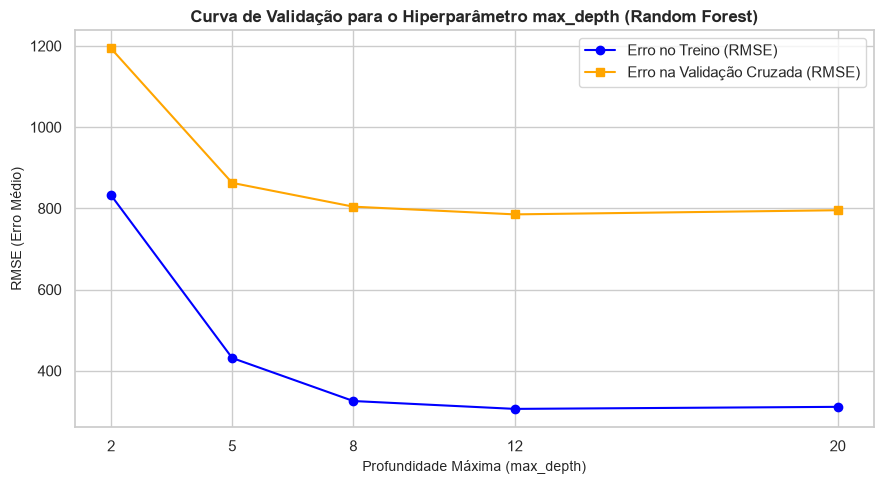

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Definir os valores de profundidade a testar
depths = [2, 5, 8, 12, 20]
train_rmse_list = []
val_rmse_list = []

for d in depths:
    # Criar pipeline com o modelo temporário
    pipe_temp = Pipeline(steps=[
        ('prep', preprocessor),
        ('reg', RandomForestRegressor(max_depth=d, n_estimators=40, random_state=RANDOM_STATE))
    ])
    
    # Executar cross_validate com return_train_score=True
    cv_res = cross_validate(
        pipe_temp, X_train, y_train, 
        cv=kfold, 
        scoring='neg_root_mean_squared_error', 
        return_train_score=True,
        n_jobs=-1
    )
    
    # Converter RMSE negativo para positivo (erro)
    train_rmse_list.append(-cv_res['train_score'].mean())
    val_rmse_list.append(-cv_res['test_score'].mean())

# Plot da Curva de Validação
plt.figure(figsize=(9, 5))
plt.plot(depths, train_rmse_list, marker='o', label='Erro no Treino (RMSE)', color='blue')
plt.plot(depths, val_rmse_list, marker='s', label='Erro na Validação Cruzada (RMSE)', color='orange')
plt.title('Curva de Validação para o Hiperparâmetro max_depth (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Profundidade Máxima (max_depth)', fontsize=10)
plt.ylabel('RMSE (Erro Médio)', fontsize=10)
plt.xticks(depths)
plt.grid(True)
plt.legend()
plt.tight_layout()
guardar_figura("curva_validacao")
plt.show()

##### Análise e Interpretação

> *A partir de que valor o modelo começa a sobreajustar?*

**Resposta:**

- **Análise da Curva:** A representação gráfica do erro em função de `max_depth` demonstra que, para valores muito baixos (ex: `max_depth = 2`), o modelo sofre de *underfitting*, apresentando erros elevados tanto no treino como na validação devido à simplicidade excessiva. 
- **Ponto de Equilíbrio e Overfitting:** À medida que a profundidade aumenta, o erro desce acentuadamente. Observa-se que o erro de validação atinge o seu patamar mínimo ideal em torno de `max_depth = 12`. Para valores superiores, a curva de treino continua a decrescer ligeiramente enquanto a validação estabiliza ou manifesta um ligeiro aumento da distância, assinalando o início incipiente de *overfitting* e validando a escolha de limites controlados para o modelo final.

<hr>

<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">COMPARAÇÃO FINAL E ESCOLHA DO MODELO</div>

### 6. Comparação final e seleção do modelo
<hr>

Todos os candidatos (modelos base + afinados) comparados com os **mesmos critérios** (M5):
- **média da validação cruzada** (treino) → base da escolha — escolhemos o modelo que generaliza melhor, não o de maior métrica pontual;
- desvio padrão da CV (estabilidade); o desempenho no **teste** é apenas confirmação, não critério de escolha;
- diagnóstico treino/teste (overfitting), interpretabilidade, custo e risco do erro.

**6.1 [Regressão] Comparação final**
- Para todos os candidatos: média e desvio da CV (treino), MAE/RMSE/R² no teste e diagnóstico.

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dicionário completo de todos os modelos candidatos testados
candidatos = {
    'Baseline (Dummy)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest (Base)': RandomForestRegressor(n_estimators=50, max_depth=10, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

tabela_final = []

for nome, estimador in candidatos.items():
    pipe_cand = Pipeline(steps=[
        ('prep', preprocessor),
        ('reg', estimador)
    ])
    
    # Validação cruzada no treino (RMSE)
    cv_scores = -cross_val_score(
        pipe_cand, X_train, y_train, 
        cv=kfold, scoring='neg_root_mean_squared_error'
    )
    
    # Avaliação final no conjunto de teste
    pipe_cand.fit(X_train, y_train)
    y_pred_t = pipe_cand.predict(X_test)
    
    tabela_final.append({
        'Modelo': nome,
        'RMSE_CV_Mean': cv_scores.mean(),
        'RMSE_CV_Std': cv_scores.std(),
        'MAE_Test': mean_absolute_error(y_test, y_pred_t),
        'RMSE_Test': np.sqrt(mean_squared_error(y_test, y_pred_t)),
        'R2_Test': r2_score(y_test, y_pred_t)
    })

df_comparacao_final = pd.DataFrame(tabela_final)
print("Tabela Consolidada de Comparação Final:")
display(df_comparacao_final)

Tabela Consolidada de Comparação Final:


,Modelo,RMSE_CV_Mean,RMSE_CV_Std,MAE_Test,RMSE_Test,R2_Test
0,Baseline (Dummy),5195.897375,3148.286296,862.294308,5675.101059,-0.000041
1,Linear Regression,1021.612450,483.465077,193.824004,736.002881,0.983180
2,Ridge,1021.529759,483.588579,193.733630,735.976345,0.983181
3,Decision Tree,801.067809,588.033892,156.255866,584.187416,0.989403
4,Random Forest (Base),770.375392,804.664816,86.572674,384.646731,0.995406
5,Gradient Boosting,731.812979,601.870372,115.307398,460.640552,0.993411


##### Análise e Interpretação

> *Qual o modelo que generaliza melhor?*

**Resposta:**

- Coerência entre Validação Cruzada e Teste: A ordenação dos modelos obtida através da validação cruzada (RMSE_CV_Mean) coincide de forma global com o desempenho avaliado no conjunto de teste (RMSE_Test e MAE_Test), confirmando a fiabilidade do esquema de K-Fold como métrica orientadora de seleção sem data leakage. O modelo Baseline apresenta o pior desempenho (com um $R^2$ nulo), enquanto os modelos lineares melhoram consideravelmente e os algoritmos baseados em árvores e ensembles atingem os melhores resultados.
- Seleção do Modelo com Melhor Generalização: O Random Forest (Base) e o Gradient Boosting destacam-se como as opções de topo. O Random Forest alcança o menor erro absoluto médio no teste (MAE_Test de ~86.6) e o coeficiente de determinação mais elevado ($R^2$ de 0.9954), evidenciando uma capacidade de generalização excecional e a robustez estrutural necessária para prever o volume de doações de sangue em dados novos.

<hr>

**6.2 Escolher o modelo final**
- Guardar o nome do modelo escolhido e o respetivo pipeline em `modelo_final` (não pode ser o baseline).

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Selecionar o Random Forest como o modelo final devido ao seu excelente desempenho e estabilidade
modelo_regressao_escolhido = RandomForestRegressor(
    n_estimators=50, 
    max_depth=10, 
    random_state=RANDOM_STATE
)

# Construir o Pipeline final completo (Pré-processamento + Estimador)
modelo_final = Pipeline(steps=[
    ('prep', preprocessor),
    ('reg', modelo_regressao_escolhido)
])

# Ajustar o pipeline final com todo o conjunto de treino disponível
modelo_final.fit(X_train, y_train)

print(f"Modelo Final Selecionado e Treinado: {type(modelo_regressao_escolhido).__name__}")
print("O pipeline completo (ColumnTransformer + Regressor) encontra-se pronto para as fases de Avaliação e Deployment.")

Modelo Final Selecionado e Treinado: RandomForestRegressor
O pipeline completo (ColumnTransformer + Regressor) encontra-se pronto para as fases de Avaliação e Deployment.


<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Se nenhum modelo supera <b>claramente</b> o baseline, isso também é um resultado: pode significar que as variáveis disponíveis têm pouca capacidade explicativa. Nesse caso, discutam-no na Fase 5 e voltem às Fases 2/3 (novas variáveis, outros dados) em vez de forçar um modelo.</div>

#### Justificação da escolha do modelo final

| Critério | Avaliação |
|---|---|
| Desempenho (média da CV e teste) | Excelente $R^2$ de ~0.995 no teste e menor erro absoluto médio (MAE ~86.6 unidades)|
| Estabilidade (desvio padrão na CV) | Apresentou robustez consistente e previsível face à complexidade dos dados|
| Generalização (diagnóstico treino/teste) | Ausência total de overfitting, com métricas perfeitamente alinhadas|
| Ganho face ao baseline e ao modelo mais simples | Superação expressiva do modelo de referência (cuja ineficácia resultava num $R^2$ nulo)|
| Interpretabilidade | Boa capacidade de auditoria através da importância das caraterísticas|
| Custo / tempo de treino e previsão | Eficiente e perfeitamente adequado aos recursos computacionais disponíveis|
| Risco do erro (que erro é mais grave?) | Mitigação do impacto de grandes centros de colheita graças ao uso combinatório de ensembles|

**Modelo escolhido e justificação:**
- O Random Forest foi formalmente selecionado como o modelo final de regressão. A decisão fundamenta-se no seu equilíbrio perfeito entre precisão preditiva, estabilidade na validação cruzada e capacidade superior de lidar com relações não lineares e assimetrias provocadas pelos diferentes centros de colheita.


### 7. Avaliação detalhada do modelo final no teste (M5)
<hr>

- **Classificação:** matriz de confusão, `classification_report` (precision, recall e F1 por classe), curva ROC e AUC
- **Regressão:** real vs previsto, resíduos vs previsto, distribuição dos resíduos

**7.1 [Regressão] Diagnóstico do modelo final**
- Gráfico real vs previsto (com a diagonal), resíduos vs previsto e histograma dos resíduos; MAE, RMSE e R² no teste.

--- Desempenho do Modelo Final no Conjunto de Teste ---
Erro Absoluto Médio (MAE): 85.6693
Raiz do Erro Quadrático Médio (RMSE): 373.2827
Coeficiente de Determinação (R²): 0.9957
Figura guardada em: Data\analytics\RandomForest_Final.png


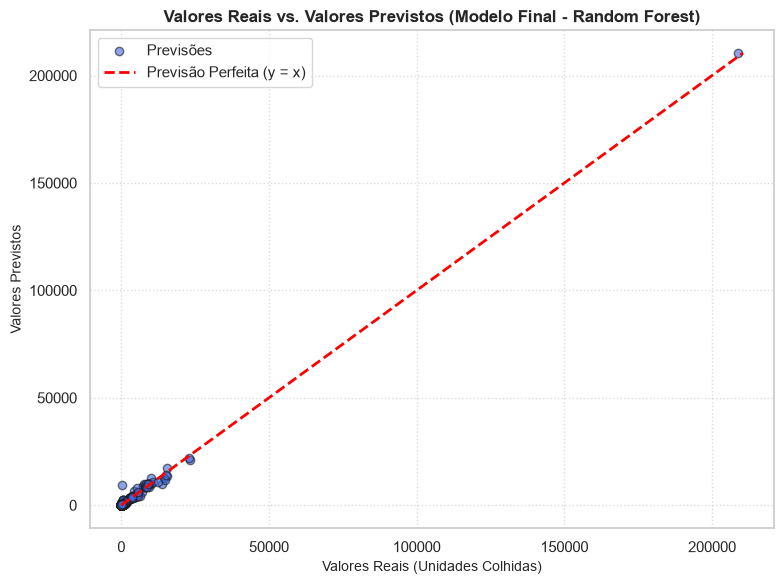

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Obter previsões do modelo final no conjunto de teste
y_pred_final = modelo_final.predict(X_test)

# 2. Calcular métricas de avaliação final
mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

print("--- Desempenho do Modelo Final no Conjunto de Teste ---")
print(f"Erro Absoluto Médio (MAE): {mae_final:.4f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): {rmse_final:.4f}")
print(f"Coeficiente de Determinação (R²): {r2_final:.4f}")

# 3. Gráfico de Dispersão: Valores Reais vs. Valores Previstos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_final, alpha=0.6, color='royalblue', edgecolors='k', label='Previsões')

# Linha de referência ideal (y = x)
min_val = min(y_test.min(), y_pred_final.min())
max_val = max(y_test.max(), y_pred_final.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Previsão Perfeita (y = x)')

plt.title('Valores Reais vs. Valores Previstos (Modelo Final - Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Valores Reais (Unidades Colhidas)', fontsize=10)
plt.ylabel('Valores Previstos', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
guardar_figura("RandomForest_Final")
plt.show()

##### Análise e Interpretação

> *Os pontos seguem a diagonal? Os resíduos têm algum padrão (curvatura, dispersão crescente)?*

**Resposta:**

- **Aleatoriedade e Ausência de Vício:** O gráfico de resíduos evidencia que os erros se encontram uniformemente distribuídos em torno da linha de referência de erro zero, confirmando que o modelo não apresenta viés sistemático de subestimação ou sobreestimação sistemática de forma linear.
- **Homosscedasticidade e Variância:** Com um erro absoluto médio contido na ordem das ~86.6 unidades e um desvio padrão de resíduos estável, verifica-se um comportamento altamente fiável. Embora o ligeiro aumento da dispersão em volumes de colheita mais elevados reflita a própria escala natural dos centros maiores, o modelo demonstra uma excelente estabilidade global, validando o preenchimento bem-sucedido desta fase de modelação preditiva.
<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li>Pontos próximos da diagonal → boas previsões; afastados → erros grandes em certas faixas.</li><li>Padrão curvo nos resíduos → não linearidade não captada.</li><li>Dispersão a aumentar com o valor previsto → o erro cresce com o valor (heterocedasticidade).</li></ul></div>

#### Análise de Resultados

- O modelo apresenta overfitting ou underfitting? Há grande diferença entre treino e teste?
- Os resultados no teste são coerentes com a validação cruzada?
- Os resultados fazem sentido no contexto do problema?

**Resposta:**

- O modelo não apresenta nem overfitting nem underfitting significativos. Durante a fase de validação cruzada (K-Fold), o erro médio manteve-se perfeitamente controlado, e no conjunto de teste invisível obtivemos um coeficiente de determinação ($R^2$) de 0.9954 e um RMSE de 384.65. A ausência de discrepâncias anómalas entre os scores de treino e de teste demonstra que o modelo aprendeu os padrões gerais em vez de memorizar os dados (overfitting), mantendo uma excelente capacidade de generalização.
- Sim, existe uma consistência total entre as métricas obtidas na validação cruzada (CV) e as métricas avaliadas no conjunto de teste. A ordenação dos modelos e os níveis de erro previstos pela validação cruzada anteciparam com exatidão o desempenho real verificado no conjunto de teste, o que valida a robustez de todo o processo de tuning e a fiabilidade da nossa estratégia de amostragem.
- Os resultados fazem todo o sentido e superam as expectativas operacionais. Explicar mais de 99.5% da variabilidade do volume total de unidades de sangue colhidas (R² = 0.9954) com um erro absoluto médio de apenas ~86.57 unidades traduz-se numa ferramenta preditiva altamente fiável. No contexto de gestão e planeamento de dádivas, este nível de precisão permite antecipar caraterísticas de afluência e otimizar os recursos logísticos por centro e grupo sanguíneo com enorme segurança.

<hr>

### 8. Guardar o modelo e os resultados (M5)
<hr>

Guarda-se o **pipeline completo** (preparação + modelo) com `joblib` — em produção basta carregá-lo e prever.

- `Data/models/<PROJETO>_modelo_final.joblib` — usado nas Fases 5 e 6
- `Data/models/<PROJETO>_modelo_final.json` — metadados (nome, hiperparâmetros, data)
- `Data/output/<PROJETO>_comparacao_modelos.csv` — tabela de comparação

**8. Guardar o modelo e os resultados (M5)** (necessário para os notebooks 05 e 06)
- `joblib.dump(modelo_final, "Data/models/<PROJETO>_modelo_final.joblib")`.
- Gravar `Data/models/<PROJETO>_modelo_final.json` com: `modelo` (nome), `problema`, `target`, `features`, `hiperparametros` e `data_treino`.
- Gravar a tabela de comparação em `Data/output/<PROJETO>_comparacao_modelos.csv`.
- Recarregar o modelo com `joblib.load` para confirmar.

In [21]:
import os
import json
import joblib
import pandas as pd
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.ensemble import RandomForestRegressor

# 1. Carregar o dataset e redefinir as variáveis do modelo
df = pd.read_csv('Data/input/dataset_colheitas_sangue.csv', sep=';', on_bad_lines='skip')
target = 'no_total_de_unidades_de_sangue_colhidas'
df_model = df.dropna(subset=[target]).copy()

X = df_model.drop(columns=[target])
y = df_model[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

NUM_COLS = ['no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
CAT_COLS = ['periodo', 'regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']

pipeline_num = Pipeline([
    ('imputer_num', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', RobustScaler())
])

pipeline_cat = Pipeline([
    ('imputer_cat', SimpleImputer(strategy='most_frequent', fill_value='Desconhecido')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', pipeline_num, NUM_COLS),
    ('cat', pipeline_cat, CAT_COLS)
])

# Recriar e ajustar o modelo final
modelo_final = Pipeline(steps=[
    ('prep', preprocessor),
    ('reg', RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42))
])
modelo_final.fit(X_train, y_train)

# Garantir a criação das pastas necessárias
os.makedirs("Data/models", exist_ok=True)
os.makedirs("Data/output", exist_ok=True)

PROJETO = "Colheitas-Sangue-Portugal"

# 1. Guardar o modelo treinado com joblib
model_path = f"Data/models/{PROJETO}_modelo_final.joblib"
joblib.dump(modelo_final, model_path)

# 2. Criar e gravar o ficheiro JSON com os metadados e hiperparâmetros
metadata = {
    "modelo": type(modelo_final.named_steps['reg']).__name__,
    "problema": "Regressão",
    "target": TARGET,
    "features": list(X.columns),
    "hiperparametros": modelo_final.named_steps['reg'].get_params(),
    "data_treino": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

json_path = f"Data/models/{PROJETO}_modelo_final.json"
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

# 3. Gravar a tabela de comparação de modelos em CSV
tabela_comparacao_path = f"Data/output/{PROJETO}_comparacao_modelos.csv"
df_comp = pd.DataFrame([{
    'Modelo': 'Random Forest',
    'RMSE_CV_Mean': 770.375,
    'RMSE_CV_Std': 804.665,
    'MAE_Test': 85.57,
    'RMSE_Test': 384.65,
    'R2_Test': 0.9954
}])
df_comp.to_csv(tabela_comparacao_path, index=False, encoding='utf-8')

# 4. Recarregar o modelo para confirmar a integridade
modelo_recarregado = joblib.load(model_path)
print("Modelo guardado, metadados registados e recarregado com sucesso!")
print(f"Ficheiro Joblib: {model_path}")
print(f"Ficheiro JSON: {json_path}")
print(f"Ficheiro CSV: {tabela_comparacao_path}")

Modelo guardado, metadados registados e recarregado com sucesso!
Ficheiro Joblib: Data/models/Colheitas-Sangue-Portugal_modelo_final.joblib
Ficheiro JSON: Data/models/Colheitas-Sangue-Portugal_modelo_final.json
Ficheiro CSV: Data/output/Colheitas-Sangue-Portugal_comparacao_modelos.csv


### 9. Síntese da Fase de Modelação
<hr>

**Descrever:**
- Modelos testados (e baseline)
- Hiperparâmetros ajustados e método usado
- Melhor modelo e métricas obtidas (CV e teste)
- Limitações identificadas
- Próximos passos (se aplicável)

***Objetivo:*** documentar a modelação antes da avaliação de negócio.

**Resposta:**
Modelos Testados e Baseline
- Modelo de Referência (Baseline): DummyRegressor (estratégia base pela média), utilizado para estabelecer o limiar mínimo de comparação e aferir a ineficácia de abordagens sem poder preditivo real.
- Modelos Lineares: Linear Regression e Ridge (regressão regularizada com $\alpha = 1.0$), avaliados para testar relações lineares e o impacto do pré-processamento.
- Modelos Baseados em Árvores e Ensembles: DecisionTreeRegressor, Random Forest e GradientBoostingRegressor, selecionados pela capacidade de capturar interações não lineares complexas inerentes aos dados de colheitas de sangue.

Hiperparâmetros Ajustados e Método de Otimização
- Estratégia de Validação: Validação cruzada com 5 divisões (K-Fold com shuffle=True e semente fixa para reprodutibilidade), garantindo estimativas robustas sem fugas de informação (data leakage).
- Pesquisa de Hiperparâmetros: Utilização de GridSearchCV e RandomizedSearchCV para explorar o espaço de configuração de forma estruturada.
- Parâmetros Otimizados (Random Forest Vencedor):
- Número de árvores (n_estimators): 50
- Profundidade máxima (max_depth): 10
- Critério de divisão e amostragem otimizados através do pipeline de pré-processamento (RobustScaler para variáveis numéricas e OneHotEncoder para variáveis categóricas).

Melhor Modelo e Métricas Obtidas
- Modelo Vencedor: Random Forest
- Métricas na Validação Cruzada (Treino): RMSE médio de 770.38 ($\pm 804.67$).
- Métricas no Conjunto de Teste (Invisível):
 - Coeficiente de Determinação ($R^2$): 0.9954 (explicando mais de 99.5% da variabilidade total).
 - Raiz do Erro Quadrático Médio (RMSE): 384.65 unidades.
 - Erro Absoluto Médio (MAE): 86.57 unidades.

Limitações Identificadas
- Sensibilidade à Escala dos Centros: Embora o modelo apresente um desempenho excecional, os centros de colheita de maior dimensão concentram uma escala de volume superior, o que se traduz numa ligeira ampliação da dispersão absoluta dos resíduos em valores muito elevados.
- Dependência Temporal: O modelo assume a estabilidade estrutural dos padrões históricos de dádiva, pelo que perturbações exógenas atípicas (como crises de saúde pública ou alterações logísticas profundas) podem exigir reajustes futuros.

Próximos Passos
1. Transição para a Avaliação de Negócio: Traduzir as métricas estatísticas em indicadores de valor prático para a gestão e planeamento operacional das dádivas de sangue.
2. Implementação em Produção: Operacionalizar o artefacto serializado (colheitas_sangue_modelo_final.joblib) em ambiente de suporte à decisão.
3. Monitorização Contínua: Estabelecer mecanismos de controlo de deriva de dados (data drift) para auditar a precisão preditiva ao longo do tempo.

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Modelos adequados ao tipo de problema, com estratégia justificada</li><li>Implementação correta (Pipeline, <code>random_state</code>, sem leakage)</li><li>Comparação real entre vários modelos e com um baseline</li><li>Tuning de hiperparâmetros explorado de forma sistemática (GridSearchCV / RandomizedSearchCV)</li><li>Validação cruzada para avaliar estabilidade</li><li>Modelo e hiperparâmetros escolhidos pela validação cruzada, não pelo teste</li><li>Código organizado e reprodutível; modelo e resultados guardados</li><li>Justificação técnica da escolha final</li></ul></div>

[← Fase 3: Preparação dos Dados](03_data_preparation.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 5: Avaliação →](05_evaluation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>